In [115]:
import logging
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.metrics.pairwise import euclidean_distances, rbf_kernel
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from _utilities.stupidloggen import StupidLogGenerator

ROOT_DIR = os.environ["VIRTUAL_ENV"][:-5]
sys.path.append(ROOT_DIR)

In [116]:
PATH_REAL_DATA = "data/preprocessed_real_data.csv"
PATH_SYNTHETIC_DATA = "data/synthetic/"
PATH_FOLDER_MODELS = "models/"

In [117]:
logger = StupidLogGenerator.initLogger()

In [118]:
# Real Dataset
real_df = pd.read_csv(PATH_REAL_DATA)

# Target Column
target_feature = "is_recid"

# Sensitive Column
sensitive_feature = "sex"

# Synthetic Datasets
synthetic_datasets = {}

# Leaky Columns
LEAK_COLS = ["r_charge_degree", "r_charge_desc"]

X_real = real_df.drop(columns=[target_feature] + LEAK_COLS)
CATEGORICAL_COLS = X_real.select_dtypes(include=["object"]).columns.tolist()
NUMERICAL_COLS = X_real.select_dtypes(exclude=["object"]).columns.tolist()
FEATURE_ORDER = X_real.columns.tolist()


In [119]:
# Load synthetic datasets
dir_list = os.listdir(PATH_SYNTHETIC_DATA)

for file_name in dir_list:
    model_name = file_name.replace("_synthetic.csv", "").replace("lambda_", "")
    synthetic_datasets[model_name] = pd.read_csv(PATH_SYNTHETIC_DATA + file_name)

In [120]:
leaks = pd.DataFrame(columns=["column", "percent", "leak_count", "total_count"])
for col in CATEGORICAL_COLS + NUMERICAL_COLS:
    t_df = real_df.groupby(col)[target_feature].mean().to_frame().reset_index()
    n = t_df.shape[0]
    leak_count = t_df["is_recid"].value_counts().get(0, 0) + t_df[
        "is_recid"
    ].value_counts().get(1, 0)
    percent = leak_count / n * 100
    leaks.loc[len(leaks)] = [col, round(percent, 0), leak_count, n]

display(leaks)

,column,percent,leak_count,total_count
0,sex,0.0,0,2
1,age_cat,0.0,0,3
2,race,0.0,0,3
3,c_charge_degree,0.0,0,2
4,c_charge_desc,57.0,248,437
5,age,18.0,12,65
6,juv_fel_count,55.0,6,11
7,juv_misd_count,30.0,3,10
8,juv_other_count,30.0,3,10
9,priors_count,19.0,7,37


## Downstream Classifier

### Preprocessing

In [121]:
real_train_df, real_test_df = train_test_split(real_df, test_size=0.2, random_state=42)


def build_pipeline(categorical_cols: list[str], numerical_cols: list[str]) -> Pipeline:
    """Builds a preprocessing + Logistic Regression pipeline"""

    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", "passthrough", numerical_cols),
        ]
    )

    pipeline = Pipeline(
        [
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=1000)),
        ]
    )

    return pipeline

### Train the classifier

In [122]:
def train_pipeline(
    train_df: pd.DataFrame,
    target_col: str,
    categorical_cols: list[str],
    numeric_cols: list[str],
    feature_order: list[str],
) -> Pipeline:
    """Trains a pipeline on a given dataset."""

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]

    X_train = X_train.reindex(columns=feature_order)

    pipeline = build_pipeline(categorical_cols, numeric_cols)
    pipeline.fit(X_train, y_train)

    return pipeline

### Run the training on the real dataset and the synthetic dataset 

In [123]:
# Train on the real dataset
real_model = train_pipeline(
    real_train_df, target_feature, CATEGORICAL_COLS, NUMERICAL_COLS, FEATURE_ORDER
)

synthetic_models = {}
one_class_datasets = []

# Train synthetic models
for model_name, df in synthetic_datasets.items():
    n_unique = df[target_feature].nunique()

    if n_unique < 2:
        logger.warning(f"Skipping {model_name}: Found only {n_unique} class")

    try:
        synthetic_models[model_name] = train_pipeline(
            df, target_feature, CATEGORICAL_COLS, NUMERICAL_COLS, FEATURE_ORDER
        )
        logger.info(f"Successfully trained: {model_name}")
    except Exception as e:
        logger.error(f"Failed to train {model_name}: {e}")

[INFO]: Successfully trained: ctgan
[INFO]: Successfully trained: ctgan
[INFO]: Successfully trained: FairGAN_0.0
[INFO]: Successfully trained: FairGAN_0.0
[INFO]: Successfully trained: FairGAN_0.1
[INFO]: Successfully trained: FairGAN_0.1
[INFO]: Successfully trained: FairGAN_0.5
[INFO]: Successfully trained: FairGAN_0.5
[INFO]: Successfully trained: FairGAN_0.7
[INFO]: Successfully trained: FairGAN_0.7
[INFO]: Successfully trained: FairGAN_1.0
[INFO]: Successfully trained: FairGAN_1.0
[INFO]: Successfully trained: TabFairGAN_0.0
[INFO]: Successfully trained: TabFairGAN_0.0
[INFO]: Successfully trained: TabFairGAN_0.1
[INFO]: Successfully trained: TabFairGAN_0.1
[INFO]: Successfully trained: TabFairGAN_0.5
[INFO]: Successfully trained: TabFairGAN_0.5
[INFO]: Successfully trained: TabFairGAN_0.7
[INFO]: Successfully trained: TabFairGAN_0.7
[INFO]: Successfully trained: TabFairGAN_1.0
[INFO]: Successfully trained: TabFairGAN_1.0
[INFO]: Successfully trained: tvae
[INFO]: Successfully tr

## Evaluation Definitions

#### Fairness Metrics

In [124]:
# Fairness Metrics Definition
# Note to self: Always sort groups first since order isn't guaranteed i.e. results may flip


def demographic_parity(y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    rates = [y_pred[sensitive == g].mean() for g in groups]
    return abs(rates[0] - rates[1])


def disparate_impact(y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    rate_0 = y_pred[sensitive == groups[0]].mean()
    rate_1 = y_pred[sensitive == groups[1]].mean()
    return min(rate_0 / (rate_1 + 1e-6), rate_1 / (rate_0 + 1e-6))


def equal_opportunity(
    y_true: pd.Series, y_pred: pd.Series, sensitive: pd.Series
) -> float:
    groups = sorted(sensitive.unique())
    tprs = []

    for g in groups:
        mask = sensitive == g
        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        tprs.append(tp / (tp + fn + 1e-6))

    return abs(tprs[0] - tprs[1])


def equalized_odds(y_true: pd.Series, y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    tpr_list, fpr_list = [], []

    for g in groups:
        mask = sensitive == g

        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        fp = ((y_pred == 1) & (y_true == 0) & mask).sum()
        tn = ((y_pred == 0) & (y_true == 0) & mask).sum()

        tpr = tp / (tp + fn + 1e-6)
        fpr = fp / (fp + tn + 1e-6)

        tpr_list.append(tpr)
        fpr_list.append(fpr)

    return abs(tpr_list[0] - tpr_list[1]) + abs(fpr_list[0] - fpr_list[1])


# Fairness Metrics Evaluation
def evaluate_fairness(
    model: Pipeline, test_df: pd.DataFrame, target_col: str, sensitive_col: str
) -> dict:
    """
    Evaluates fairness metrics on the real test set.
    """

    # Split test data
    X_test = test_df.drop(columns=[target_col])
    y_true = test_df[target_col]
    sensitive = test_df[sensitive_col]

    # Predict using trained pipeline
    y_pred = model.predict(X_test)
    y_pred = pd.Series(y_pred, index=X_test.index)

    # Compute fairness metrics
    results = {
        "demographic_parity": demographic_parity(y_pred, sensitive),
        "disparate_impact": disparate_impact(y_pred, sensitive),
        "equal_opportunity": equal_opportunity(y_true, y_pred, sensitive),
        "equalized_odds": equalized_odds(y_true, y_pred, sensitive),
    }

    return results

In [125]:
# Comparison of Fairness Across Datasets
fairness_results = {}

# Real dataset baseline
fairness_results["Real"] = evaluate_fairness(
    real_model,
    real_test_df,
    target_col=target_feature,
    sensitive_col=sensitive_feature,
)

# Synthetic models
for name, model in synthetic_models.items():
    fairness_results[name] = evaluate_fairness(
        model, real_test_df, target_col=target_feature, sensitive_col=sensitive_feature
    )

fairness_df = pd.DataFrame(fairness_results).T
# fairness_df

#### Synthetic Data Realism Metric

In [126]:
def estimate_gamma(X: np.ndarray) -> float:
    """
    Estimates gamma using the median heuristic.
    """
    dists = euclidean_distances(X, X)
    dists = dists[dists > 0]  # remove zeros (distance to itself)

    median_dist = np.median(dists)

    gamma = 1 / (2 * (median_dist**2 + 1e-6))
    return gamma


# Preprocessing for MMD
def preprocess_mmd(df: pd.DataFrame, target_col: str) -> pd.DataFrame:
    """
    Converts dataframe into numeric matrix for MMD:
    - Drops target column
    - One-hot encodes categorical features
    """
    X = df.drop(columns=[target_col])
    X = pd.get_dummies(X, drop_first=True)
    return X


# MMD Computation
def compute_mmd(X_real: np.ndarray, X_synth: np.ndarray, gamma=1.0) -> float:
    """
    Computes Maximum Mean Discrepancy using RBF kernel.
    """
    K_xx = rbf_kernel(X_real, X_real, gamma=gamma)
    K_yy = rbf_kernel(X_synth, X_synth, gamma=gamma)
    K_xy = rbf_kernel(X_real, X_synth, gamma=gamma)

    mmd = K_xx.mean() + K_yy.mean() - 2 * K_xy.mean()

    return mmd


# Main Evaluation Function
def evaluate_realism(
    real_df: pd.DataFrame, synth_df: pd.DataFrame, target_col: str, sample_size=1000
) -> float:
    """
    Computes MMD using random sampling + median heuristic for gamma.
    """
    X_real = preprocess_mmd(real_df, target_col)
    X_synth = preprocess_mmd(synth_df, target_col)

    X_synth = X_synth.reindex(columns=X_real.columns, fill_value=0)

    # --- SAMPLE ---
    X_real_sample = X_real.sample(n=min(sample_size, len(X_real)), random_state=42)
    X_synth_sample = X_synth.sample(n=min(sample_size, len(X_synth)), random_state=42)

    # --- Estimate gamma from REAL data ---
    gamma = estimate_gamma(X_real_sample.values)

    return compute_mmd(
        X_real_sample.values,
        X_synth_sample.values,
        gamma=gamma,
    )

In [ ]:
# Run for All Synthetic Datasets
realism_results = {}

for model_name, synth_df in synthetic_datasets.items():
    realism_results[model_name] = evaluate_realism(
        real_train_df, synth_df, target_col=target_feature, sample_size=1000
    )

realism_df = pd.DataFrame.from_dict(realism_results, orient="index", columns=["MMD"])
# realism_df

#### Utility

In [128]:
def evaluate_utility(model: Pipeline, test_df: pd.DataFrame, target_col: str) -> dict:
    """
    Evaluates predictive performance using TSTR:
    Train on (real/synthetic) → Test on REAL test data
    """
    X_test = test_df.drop(columns=[target_col])
    y_true = test_df[target_col]
    y_pred = model.predict(X_test)

    # Probabilities
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred

    results = {
        "accuracy": accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
    }

    return results

In [ ]:
utility_results = {}

# Real dataset baseline
utility_results["Real"] = evaluate_utility(
    real_model, real_test_df, target_col=target_feature
)

# Synthetic models
for model_name, model in synthetic_models.items():
    utility_results[model_name] = evaluate_utility(
        model, real_test_df, target_col=target_feature
    )

utility_df = pd.DataFrame(utility_results).T
# utility_df

## Evaluation Comparison

In [130]:
logger.setLevel(logging.INFO)

In [ ]:
sort_order = [
    "Real",
    "ctgan",
    "tvae",
    "FairGAN_0.0",
    "FairGAN_0.1",
    "FairGAN_0.5",
    "FairGAN_0.7",
    "FairGAN_1.0",
    "TabFairGAN_0.0",
    "TabFairGAN_0.1",
    "TabFairGAN_0.5",
    "TabFairGAN_0.7",
    "TabFairGAN_1.0",
]

final_df = pd.concat([utility_df, fairness_df, realism_df], axis=1)
final_df = final_df.reindex(sort_order)
final_df = final_df.fillna("-")

final_df = final_df[
    [
        "accuracy",
        "auc",
        "demographic_parity",
        "disparate_impact",
        "equal_opportunity",
        "equalized_odds",
        "MMD",
    ]
]

model_labels = []

for model_name in final_df.index:
    if model_name == "Real":
        model_labels.append("Real")
    elif "FairGAN" in model_name:
        model_name_parts = model_name.split("_")
        model_labels.append(f"{model_name_parts[0]} (λ={model_name_parts[1]})")
    else:
        model_labels.append(model_name.upper())

final_df = final_df.rename(index=dict(zip(final_df.index, model_labels)))
# final_df

# Graphs

In [ ]:
import seaborn as sns

base_palette = sns.color_palette("deep")


def get_colors(color_palette: dict, data: pd.Series) -> list:
    colors = []
    for model in data.index:
        if "Tab" in model:
            colors.append(color_palette["TabFairGAN"])
        elif "FairGAN" in model:
            colors.append(color_palette["FairGAN"])
        else:
            colors.append(color_palette[model])
    return colors


color_by_model = {
    "Real": base_palette[0],
    "CTGAN": base_palette[1],
    "TVAE": base_palette[2],
    "FairGAN": base_palette[3],
    "TabFairGAN": base_palette[4],
}

In [133]:
metric_cols = [
    "accuracy",
    "auc",
    "demographic_parity",
    "disparate_impact",
    "equal_opportunity",
    "equalized_odds",
    "MMD",
]

final_df[metric_cols] = final_df[metric_cols].apply(pd.to_numeric, errors="coerce")

os.makedirs("figures", exist_ok=True)


In [ ]:
fig_size = (6.2, 4.5)
img_format = "eps"
figure_folder = "figures/graphs"

## Statistical realism (MMD)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


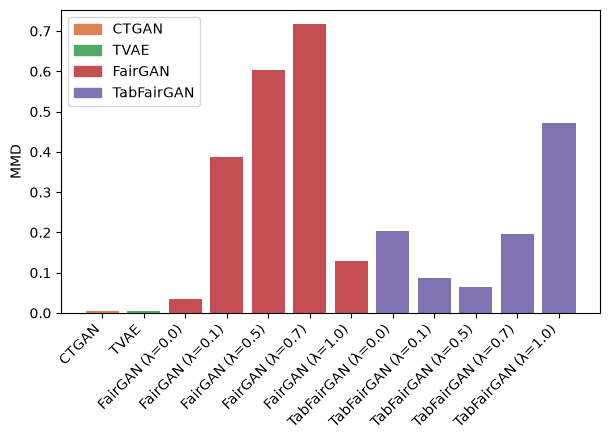

In [ ]:
mmd_data = final_df["MMD"].dropna()
mmd_colors = color_by_model.copy()
mmd_colors.pop("Real")

plt.figure(figsize=fig_size)
plt.bar(mmd_data.index, mmd_data.values, color=get_colors(color_by_model, mmd_data))
plt.ylabel("MMD")
# plt.title("Statistical realism by model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=mmd_colors[model]) for model in mmd_colors
    ],
    labels=list(mmd_colors.keys()),
    loc="upper left",
)
plt.savefig(f"{figure_folder}/stat_realism_mmd.{img_format}", dpi=300)
plt.show()

## Predictive utility (accuracy + AUC)

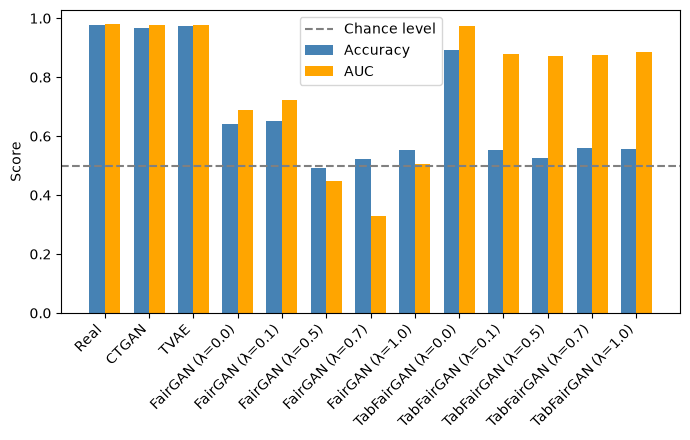

In [ ]:
utility_data = final_df[["accuracy", "auc"]].dropna()
model_names = utility_data.index
x_positions = np.arange(len(model_names))
bar_width = 0.35

plt.figure(figsize=(7, 4.5))
plt.bar(
    x_positions - bar_width / 2,
    utility_data["accuracy"],
    bar_width,
    label="Accuracy",
    color="steelblue",
)
plt.bar(
    x_positions + bar_width / 2,
    utility_data["auc"],
    bar_width,
    label="AUC",
    color="orange",
)
plt.axhline(0.5, color="gray", linestyle="--", label="Chance level")
plt.xticks(x_positions, model_names, rotation=45, ha="right")
plt.ylabel("Score")
# plt.title("Predictive utility by model")
plt.legend()
plt.tight_layout()
plt.savefig(f"{figure_folder}/predictive_utility.{img_format}", dpi=300)
plt.show()

## Trade-off across λ (FairGAN and TabFairGAN)

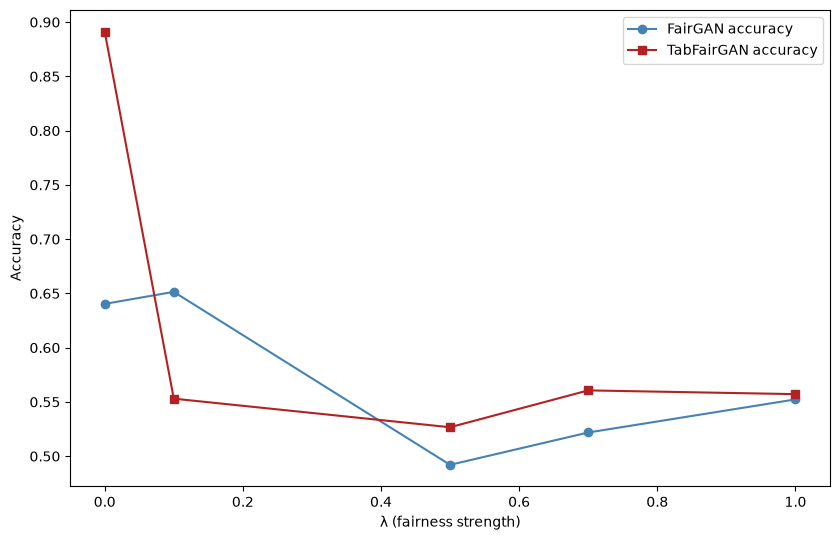

In [ ]:
fairgan_labels = [x for x in final_df.index if "FairGAN" in x and "Tab" not in x]
fairgan_lambdas = [0.0, 0.1, 0.5, 0.7, 1.0]

tabfairgan_labels = [x for x in final_df.index if "TabFairGAN" in x]
tabfairgan_lambdas = [0.0, 0.1, 0.5, 0.7, 1.0]

fairgan_accuracy = final_df.loc[fairgan_labels, "accuracy"]
tabfairgan_accuracy = final_df.loc[tabfairgan_labels, "accuracy"]

fig, ax1 = plt.subplots(figsize=(8.5, 5.5))
ax1.plot(
    fairgan_lambdas,
    fairgan_accuracy,
    marker="o",
    color="steelblue",
    label="FairGAN accuracy",
)
ax1.plot(
    tabfairgan_lambdas,
    tabfairgan_accuracy,
    marker="s",
    color="firebrick",
    label="TabFairGAN accuracy",
)
ax1.set_xlabel("λ (fairness strength)")
ax1.set_ylabel("Accuracy")
# ax1.set_title("Utility vs. λ")
ax1.legend()
plt.tight_layout()
plt.savefig(f"{figure_folder}/lambda_tradeoff.{img_format}", dpi=300)
plt.show()


## Fairness metrics

In [139]:
def format_metric_names(metric: str) -> str:
    """
    Formats metric names for LaTeX table.
    """
    if len(metric) <= 3:
        return metric.upper()
    else:
        return metric.replace("_", " ").title()


fairness_cols = [
    "demographic_parity",
    "disparate_impact",
    "equal_opportunity",
    "equalized_odds",
]

colours = plt.cm.tab10.colors[:4]

### Same graph

In [140]:
formatted_metric_names = {col: format_metric_names(col) for col in fairness_cols}

In [ ]:
fairness_data = final_df[fairness_cols].dropna()


# Plotting directly with pandas
ax = fairness_data.plot(
    kind="bar",
    figsize=(12, 6),
    color=colours[0],
    width=0.8,
    rot=45,
)

ax.set_title("Fairness Metrics Across All Models", fontsize=14, pad=15)
ax.set_ylabel("Metric Value", fontsize=11)
ax.set_xlabel("Model", fontsize=11)
ax.legend(
    [col.replace("_", " ").title() for col in fairness_cols],
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(
    f"{figure_folder}/fairness_metrics.{img_format}", dpi=300, bbox_inches="tight"
)
plt.show()

### Separate images

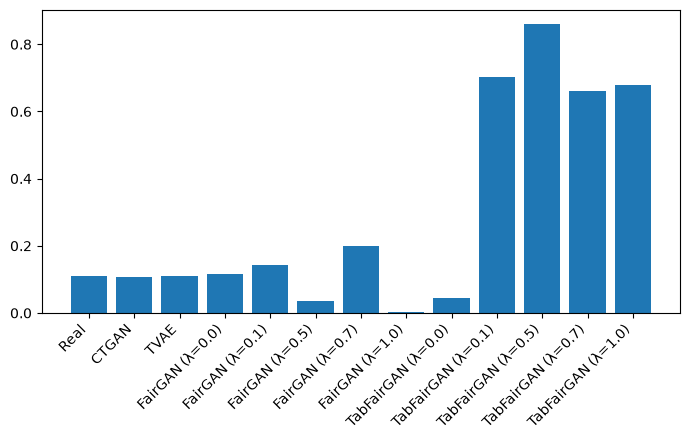

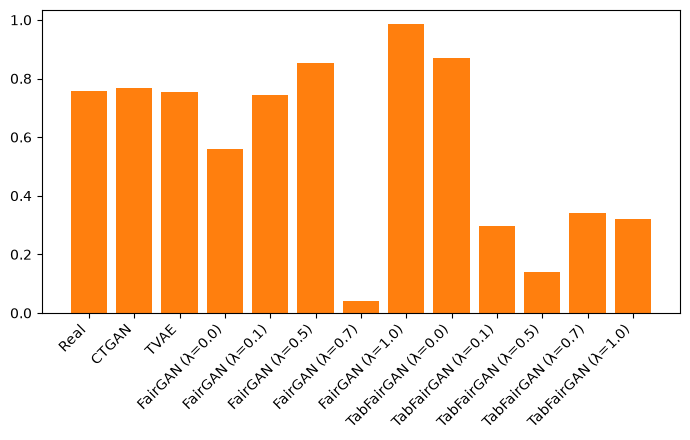

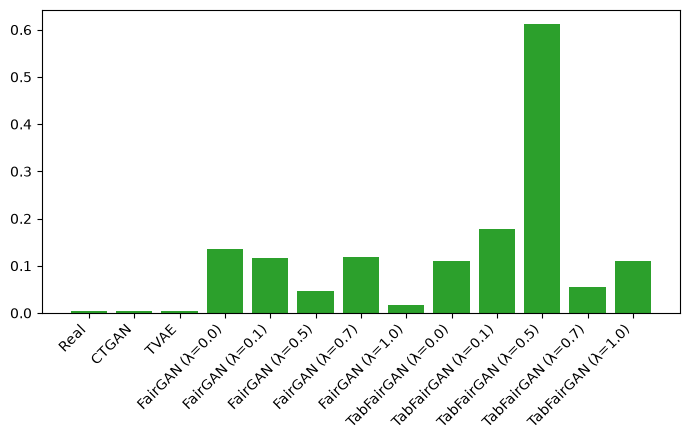

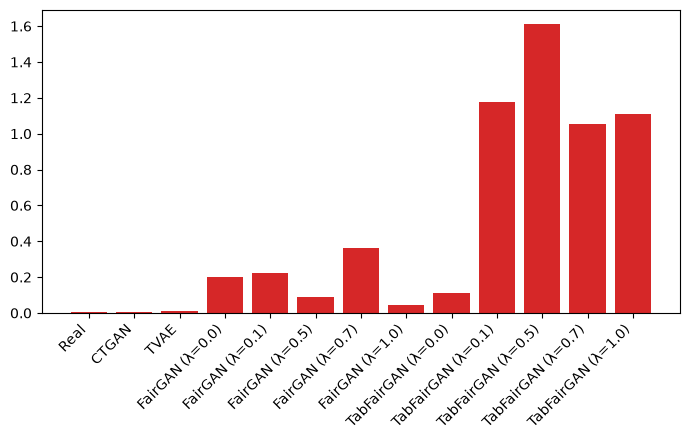

In [ ]:
for metric in fairness_cols:
    plt.figure(figsize=(7, 4.5))
    plt.bar(
        final_df.index,
        final_df[metric],
        color=colours[fairness_cols.index(metric)],
    )
    # plt.title(f"Fairness metric: {format_metric_names(idx)}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(f"{figure_folder}/fairness_{metric}.{img_format}", dpi=300)
    plt.show()

### Separate graphs, joint image

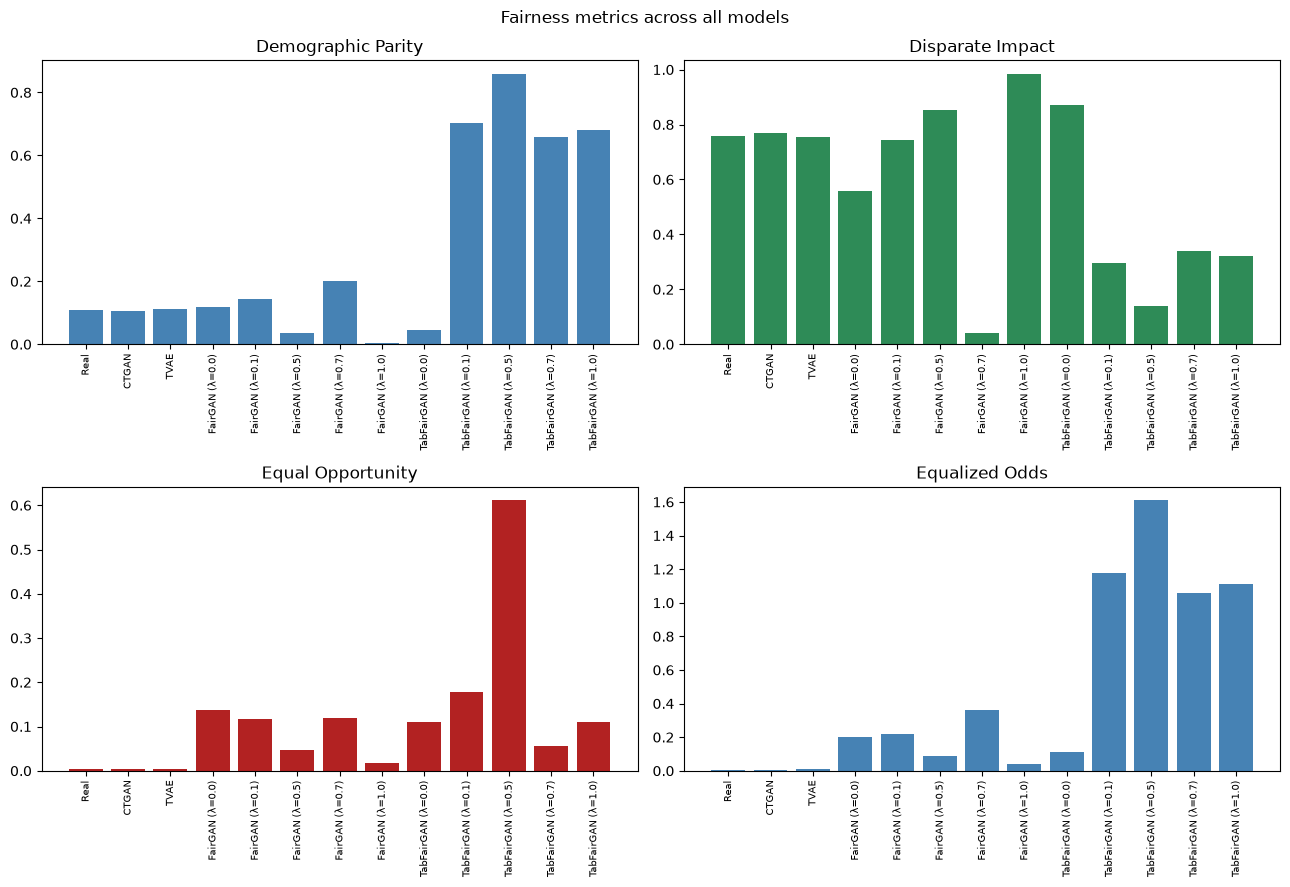

In [ ]:
# fairness_cols = [
#     "demographic_parity",
#     "disparate_impact",
#     "equal_opportunity",
#     "equalized_odds",
# ]

# fairness_data = final_df[fairness_cols].dropna()

# fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# axes[0, 0].bar(
#     fairness_data.index, fairness_data["demographic_parity"], color="steelblue"
# )
# axes[0, 0].set_title("Demographic Parity")

# axes[0, 1].bar(fairness_data.index, fairness_data["disparate_impact"], color="seagreen")
# axes[0, 1].set_title("Disparate Impact")

# axes[1, 0].bar(
#     fairness_data.index, fairness_data["equal_opportunity"], color="firebrick"
# )
# axes[1, 0].set_title("Equal Opportunity")

# axes[1, 1].bar(fairness_data.index, fairness_data["equalized_odds"], color="steelblue")
# axes[1, 1].set_title("Equalized Odds")

# for ax in axes.flat:
#     ax.tick_params(axis="x", rotation=90, labelsize=7)

# plt.suptitle("Fairness metrics across all models")
# plt.tight_layout()
# plt.savefig(f"{figure_folder}/fairness_metrics.{img_format}", dpi=300)
# plt.show()


## Result table in latex

In [ ]:
def convert_lambda_to_latex(model_name: str) -> str:
    """
    Converts model names with lambda values to LaTeX format.
    """
    if "λ" in model_name:
        parts = model_name.split(" (λ=")
        base_name = parts[0]
        lambda_value = parts[1][:-1]  # Remove the closing parenthesis
        return f"{base_name} ($\\lambda={lambda_value}$)"
    else:
        return model_name


formatted_col_names = {
    "accuracy": "Accuracy",
    "auc": "AUC",
    "demographic_parity": "DP",
    "disparate_impact": "DI",
    "equal_opportunity": "Equal Opp.",
    "equalized_odds": "Equa. Odds",
    "MMD": "MMD",
}

In [ ]:
df_for_latex = final_df.copy()
df_for_latex = df_for_latex.rename(
    mapper=formatted_col_names,
    axis="columns",
)

df_for_latex.insert(
    0, "Model", [convert_lambda_to_latex(m) for m in df_for_latex.index]
)


def strip_and_convert(model_name: str) -> str:
    """
    Strips model name and converts it for LaTeX tables.
    """
    if "λ" in model_name:
        parts = model_name.split(" (λ=")
        lambda_value = parts[1][:-1]
        return f"$\\lambda={lambda_value}$"
    else:
        return model_name


def create_subtables(df_tbl: pd.DataFrame, table_name: str) -> list[str]:
    split_dfs = {
        "Standard Models": pd.DataFrame(),
        "FairGAN": pd.DataFrame(),
        "TabFairGAN": pd.DataFrame(),
    }

    for model in df_tbl.index:
        if "Tab" in model:
            split_dfs["TabFairGAN"] = pd.concat(
                [split_dfs["TabFairGAN"], df_tbl.loc[[model]]], ignore_index=False
            )
        elif "FairGAN" in model:
            split_dfs["FairGAN"] = pd.concat(
                [split_dfs["FairGAN"], df_tbl.loc[[model]]], ignore_index=False
            )
        else:
            split_dfs["Standard Models"] = pd.concat(
                [split_dfs["Standard Models"], df_tbl.loc[[model]]], ignore_index=False
            )

    latex_code = []

    # for df_split, table_title in split_dfs.items():
    for table_title, df_split in split_dfs.items():
        df_split = pd.DataFrame(df_split)
        df_split = df_split.rename(
            mapper=formatted_col_names,
            axis="columns",
        )
        df_split.insert(0, "Model", [strip_and_convert(m) for m in df_split.index])
        sub_code = df_split.to_latex(
            index=False,
            na_rep="N/A",
            position="t",
            column_format=f"l{'c' * (len(df_split.columns) - 1)}",
            float_format="%.3f",
            header=True,
        )
        print(f"Subtable for {table_title}:\n{sub_code}\n")
    # with open(f"figures/tables/results_{table_name}.tex", "w") as latex_file:
    #     latex_file.write("\n\n".join(latex_code))
    return latex_code


# print(create_subtables(mmd_data, "stat_realism_mmd"))
# print(create_subtables(utility_data, "utility"))
create_subtables(fairness_data, "fairness")

Subtable for Standard Models:
\begin{table}[t]
\begin{tabular}{lcccc}
\toprule
Model & DP & DI & Equal Opp. & Equa. Odds \\
\midrule
Real & 0.109 & 0.757 & 0.004 & 0.006 \\
CTGAN & 0.107 & 0.768 & 0.004 & 0.004 \\
TVAE & 0.111 & 0.754 & 0.004 & 0.009 \\
\bottomrule
\end{tabular}
\end{table}


Subtable for FairGAN:
\begin{table}[t]
\begin{tabular}{lcccc}
\toprule
Model & DP & DI & Equal Opp. & Equa. Odds \\
\midrule
$\lambda=0.0$ & 0.117 & 0.559 & 0.136 & 0.200 \\
$\lambda=0.1$ & 0.143 & 0.742 & 0.116 & 0.220 \\
$\lambda=0.5$ & 0.036 & 0.854 & 0.046 & 0.088 \\
$\lambda=0.7$ & 0.200 & 0.040 & 0.119 & 0.362 \\
$\lambda=1.0$ & 0.003 & 0.985 & 0.017 & 0.042 \\
\bottomrule
\end{tabular}
\end{table}


Subtable for TabFairGAN:
\begin{table}[t]
\begin{tabular}{lcccc}
\toprule
Model & DP & DI & Equal Opp. & Equa. Odds \\
\midrule
$\lambda=0.0$ & 0.046 & 0.871 & 0.109 & 0.111 \\
$\lambda=0.1$ & 0.704 & 0.296 & 0.178 & 1.178 \\
$\lambda=0.5$ & 0.859 & 0.140 & 0.611 & 1.610 \\
$\lambda=0.7$ & 0.660

[]

### All results

In [185]:
df_for_latex = final_df.copy()
df_for_latex = df_for_latex.rename(
    mapper=formatted_col_names,
    axis="columns",
)


df_for_latex.insert(
    0, "Model", [convert_lambda_to_latex(m) for m in df_for_latex.index]
)


df_for_latex = df_for_latex[["Model", "MMD"]]

latex_code = df_for_latex.to_latex(
    index=False,
    na_rep="N/A",
    caption="Results Table",
    label="tab:table_results",
    position="h!",
    column_format=f"l{'c' * len(df_for_latex.columns)}",
    float_format="%.3f",
    header=True,
)

with open("figures/results_table.tex", "w") as result_file:
    result_file.write(latex_code)

print(latex_code)

\begin{table}[h!]
\caption{Results Table}
\label{tab:table_results}
\begin{tabular}{lcc}
\toprule
Model & MMD \\
\midrule
Real & N/A \\
CTGAN & 0.006 \\
TVAE & 0.005 \\
FairGAN ($\lambda=0.0$) & 0.036 \\
FairGAN ($\lambda=0.1$) & 0.387 \\
FairGAN ($\lambda=0.5$) & 0.604 \\
FairGAN ($\lambda=0.7$) & 0.716 \\
FairGAN ($\lambda=1.0$) & 0.130 \\
TabFairGAN ($\lambda=0.0$) & 0.205 \\
TabFairGAN ($\lambda=0.1$) & 0.088 \\
TabFairGAN ($\lambda=0.5$) & 0.066 \\
TabFairGAN ($\lambda=0.7$) & 0.196 \\
TabFairGAN ($\lambda=1.0$) & 0.472 \\
\bottomrule
\end{tabular}
\end{table}

